# AdLift - Ad Conversion Prediction
## DSAI Mini Coursework

**Student name**: Vinh Nguyen  
**Email**: congvinhnguyen.job@gmail.com  
**Discord username**: greeksiz  
**Submission date**: 2026-10-21

---

### Mark Scheme

| Section | Marks |
|---|---|
| 1 | 10 |
| 2 | 3 |
| 3 | 10 |
| 4 | 20 |
| 5 | 15 |
| 6 | 8 |
| 7 | 19 |
| 8 | 5 |
| Extension | 10 |
| **Total** | **100** |

---
# SECTION 1 - Understanding the Problem *(10 marks)*

**1.1** *(2 marks)* What is the target variable? How do you construct it from the available tables? Is this a classification or regression problem?

The target is `converted`, which is 1 if the user made a purchase and 0 if they did not. `users.csv` does not have this column, so I build it myself: a user gets 1 if their `user_id` appears in `conversions.csv`. I checked that nobody appears there twice, so one row in `conversions.csv` means one converted user.

Because the answer is yes or no, this is a binary classification problem. In practice we care most about the predicted probability, since AdLift will sort users by it and target the top 20%.

---

**1.2** *(2 marks)* Only ~15% of users convert. If a model simply predicts 'no conversion' for every user, what accuracy does it get? Why is this useless, and what metric should you use instead?

In this data 14.7% of users convert, so a model that always says "no" is right for the other 85.3% and gets 85.3% accuracy. That sounds good, but the model never finds a single buyer, so AdLift would have nobody to send ads to. Accuracy looks high only because most users are in the "no" class.

A better choice is AUC-ROC, which measures how often the model gives a buyer a higher score than a non-buyer. Since the budget only covers 20% of users, I also use the capture rate at 20%, which shows how many of the real buyers end up in the group we target.

---

**1.3** *(2 marks)* `was_clicked` in `ad_exposures` indicates that a user clicked an ad. Explain why click-through behaviour is a strong predictor of conversion. Is it possible that including it causes any form of data leakage?

When someone clicks an ad, they are interested enough to visit the shop, which puts them one step closer to buying. Age or gender only tell us who the person is, while a click tells us what they want right now. The data shows this clearly: users who clicked at least one ad converted at 51%, compared with 7.5% for users who saw ads but never clicked.

It can cause leakage. The clicks and the purchases come from the same time period, and there is no cut-off date between "past behaviour" and "the future we want to predict". If a user clicked an ad and bought in the same visit, the click is almost part of the purchase, and the model would be partly looking at the answer. I checked the dates to see how big this risk is. No ad was shown to a user after they bought, and the median time between a click and the purchase is about 32 days, so in this dataset the clicks mostly happen well before the purchase. In a real system I would still only use clicks from before the period we are predicting.

When I removed the three click features, the CV AUC dropped from 0.884 to 0.790 (Section 5), so the model relies on clicks a lot.

---

**1.4** *(2 marks)* The data contains some users who converted without ever being exposed to an ad (`ad_exposures.csv` has no record for them). What does this tell you about the nature of conversions in this dataset?

419 users never saw any ad, and 15 of them still bought something (3.6%). So people can buy without ads, for example by searching on Google, coming to the website directly, or hearing about the shop from friends.

This means the model predicts who is likely to buy, which is a different question from who buys because of an ad. Some of the users we target would probably buy anyway. AdLift also chose who saw ads in the first place, so the gap between exposed users (15.3%) and non-exposed users (3.6%) mixes the effect of the ads with the way those users were chosen. To measure what the ads really add, AdLift would need a control group of users who are not shown ads.

---

**1.5** *(2 marks)* AdLift's budget allows targeting only the top 20% of users. In your own words, describe what the **conversion capture rate** measures and why it is a better business metric than AUC alone.

To get the capture rate, I sort all users by their score, take the top 20%, and count how many of all the real buyers are in that group. If we picked 20% of users at random, we would catch about 20% of the buyers, so a capture rate of 60% would mean the model finds three times as many buyers with the same budget.

AUC is useful for comparing models, but it looks at every possible cut-off, including ones AdLift will never use, like targeting 2% or 90% of users. Two models can have the same AUC and still perform differently in the top 20%. Capture rate measures the model at the budget AdLift really has, and it is easy to turn into money and to explain to a campaign manager.

---
# SECTION 2 - Setup & Data Loading *(3 marks)*

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

In [2]:
# *(3 marks)* Load all four tables. Parse date columns. Print shape and first few rows.
users       = pd.read_csv('data/users.csv')
exposures   = pd.read_csv('data/ad_exposures.csv',  parse_dates=['exposure_date'])
conversions = pd.read_csv('data/conversions.csv',   parse_dates=['conversion_date'])
campaigns   = pd.read_csv('data/campaigns.csv',     parse_dates=['start_date','end_date'])

from matplotlib.ticker import PercentFormatter
tables = {'users': users, 'ad_exposures': exposures, 'conversions': conversions, 'campaigns': campaigns}
for name, df in tables.items():
    print(f'{name}: {df.shape[0]:,} rows x {df.shape[1]} columns')
    display(df.head(3))

users: 8,000 rows x 8 columns


,user_id,age_group,gender,top_interest,is_loyalty_member,device_preference,days_since_last_visit,n_past_purchases
0,U00000001,18-24,F,food,0,desktop,4.0,1
1,U00000002,25-34,F,sports,1,mobile,43.0,2
2,U00000003,25-34,X,finance,0,mobile,21.0,5


ad_exposures: 23,906 rows x 8 columns


,exposure_id,user_id,campaign_id,exposure_date,channel,creative_type,ad_position,was_clicked
0,E0000000001,U00000001,C08,2025-05-01,video,in_stream,1.0,0
1,E0000000002,U00000001,C04,2025-03-18,video,pre_roll,1.0,0
2,E0000000003,U00000001,C08,2025-05-01,video,in_stream,3.0,0


conversions: 1,178 rows x 5 columns


,conversion_id,user_id,conversion_date,order_value,last_campaign_id
0,CV00000001,U00000004,2025-05-18,59.74,C08
1,CV00000002,U00000007,2025-03-26,237.56,C01
2,CV00000003,U00000016,2025-05-08,136.65,C03


campaigns: 8 rows x 8 columns


,campaign_id,campaign_name,channel,creative_type,budget_gbp,base_cvr,start_date,end_date
0,C01,summer_sale,social_media,carousel,25000,0.12,2025-01-06,2025-03-23
1,C02,summer_sale,search,text_ad,40000,0.20,2025-02-09,2025-04-06
2,C03,new_arrivals,display,banner,15000,0.05,2025-01-26,2025-04-17


---
# SECTION 3 - Exploring the Data (EDA) *(10 marks)*

### 3.1 Data Quality & Target Construction *(3 marks)*

In [3]:
# *(3 marks)*
# 1. Nulls per table
for name, df in tables.items():
    nulls = df.isna().sum()
    print(f'{name:13s} nulls:', nulls[nulls > 0].to_dict() or 'none')
print('Converters with missing last_campaign_id that never saw an ad:',
      (~conversions.loc[conversions.last_campaign_id.isna(), 'user_id'].isin(exposures.user_id)).sum())

# 2. Deduplicate ad_exposures
content_cols = [c for c in exposures.columns if c != 'exposure_id']
print('\nDuplicate exposure_id values         :', exposures['exposure_id'].duplicated().sum())
print('Rows identical apart from exposure_id:', exposures.duplicated(subset=content_cols).sum())
# The log is sorted by user_id except for a block at the very end
user_num = exposures['user_id'].str[1:].astype(int)
tail_start = (user_num.diff() < 0).idxmax()
n_tail = len(exposures) - tail_start
n_tail_copies = exposures.duplicated(subset=content_cols).loc[tail_start:].sum()
print(f'Rows after the user_id order breaks  : {n_tail} (from {exposures.exposure_id[tail_start]}), '
      f'{n_tail_copies} of them copy an earlier row')
n_before = len(exposures)
exposures = exposures.drop_duplicates(subset=content_cols).reset_index(drop=True)
print(f'ad_exposures: {n_before:,} -> {len(exposures):,} rows after dedup')

# 3. Binary target
users['converted'] = users['user_id'].isin(conversions['user_id']).astype(int)

# 4. Overall conversion rate
print(f"\nConversion rate: {users['converted'].mean():.2%} ({users['converted'].sum():,} of {len(users):,} users)")
print(f"Conversion rate where days_since_last_visit is missing: {users.loc[users.days_since_last_visit.isna(), 'converted'].mean():.1%}")
print('Max conversions per user:', conversions['user_id'].value_counts().max())

# 5. Users with no ad exposure
no_exp = ~users['user_id'].isin(exposures['user_id'])
print(f'Users never served an ad: {no_exp.sum()} ({no_exp.mean():.1%}), conversion rate '
      f'{users.loc[no_exp, "converted"].mean():.1%} vs {users.loc[~no_exp, "converted"].mean():.1%} for exposed users')

# Timing checks
print('\nExposure dates  :', exposures.exposure_date.min().date(), '->', exposures.exposure_date.max().date())
print('Conversion dates:', conversions.conversion_date.min().date(), '->', conversions.conversion_date.max().date())
print('Conversions per month:', conversions.conversion_date.dt.strftime('%Y-%m').value_counts().sort_index().to_dict())
ends = exposures.merge(campaigns[['campaign_id', 'end_date']], on='campaign_id')
print(f"Exposures dated on their campaign's end_date: {(ends.exposure_date == ends.end_date).mean():.1%}")
paths = exposures.merge(conversions[['user_id', 'conversion_date']], on='user_id')
print('Exposures dated after the user converted:', (paths.exposure_date > paths.conversion_date).sum())
clicks = paths[paths.was_clicked == 1]
print('Clicked exposures on the conversion day:', (clicks.exposure_date == clicks.conversion_date).sum(),
      '| median days from click to conversion:', (clicks.conversion_date - clicks.exposure_date).dt.days.median())
late = conversions[conversions.conversion_date > exposures.exposure_date.max() + pd.Timedelta(days=30)]
print(f'Conversions more than 30 days after the last logged ad: {len(late)}, '
      f'all from never-exposed users: {late.user_id.isin(users.loc[no_exp, "user_id"]).all()}')

users         nulls: {'days_since_last_visit': 370}
ad_exposures  nulls: {'ad_position': 921}
conversions   nulls: {'order_value': 72, 'last_campaign_id': 15}
campaigns     nulls: none
Converters with missing last_campaign_id that never saw an ad: 15

Duplicate exposure_id values         : 0
Rows identical apart from exposure_id: 588
Rows after the user_id order breaks  : 40 (from E0000023867), 40 of them copy an earlier row
ad_exposures: 23,906 -> 23,318 rows after dedup

Conversion rate: 14.72% (1,178 of 8,000 users)
Conversion rate where days_since_last_visit is missing: 14.9%
Max conversions per user: 1
Users never served an ad: 419 (5.2%), conversion rate 3.6% vs 15.3% for exposed users

Exposure dates  : 2025-01-06 -> 2025-05-01
Conversion dates: 2025-01-13 -> 2026-06-06
Conversions per month: {'2025-01': 3, '2025-02': 14, '2025-03': 56, '2025-04': 232, '2025-05': 863, '2025-06': 1, '2025-07': 1, '2025-08': 1, '2025-12': 1, '2026-01': 1, '2026-04': 1, '2026-05': 3, '2026-06': 1}


**Commentary** - what did you find?

There are a few missing values. `days_since_last_visit` is missing for 370 users, `ad_position` for 921 impressions, `order_value` for 72 conversions and `last_campaign_id` for 15 conversions. The 15 missing campaigns belong exactly to the 15 buyers who never saw an ad, so those gaps make sense. Users with a missing `days_since_last_visit` convert at 14.9%, about the same as everyone else, so filling them with the median is fine.

The duplicates were the most surprising part. The brief says to remove duplicates using `exposure_id`, but every `exposure_id` is unique, so that removes nothing. When I compared all the other columns, 588 rows were exact copies of another row, which means the duplicated impressions were given new ids. The last 40 rows of the file also break the user order and all copy earlier rows, so they are clearly logging errors. I removed duplicates using every column except the id, which took the table from 23,906 to 23,318 rows.

After that, the conversion rate is 14.72% (1,178 of 8,000 users), and nobody converts more than once. 419 users (5.2%) never saw an ad, and they convert at only 3.6% compared with 15.3% for users who saw ads.

The dates are also worth noting. The ads only run from January to 1 May 2025, much shorter than the period in the brief, and 93% of purchases happen in April and May 2025. 82% of the impressions are dated on the last day of their campaign, so the ad server probably saves them all at once when a campaign ends. Because of this, the exposure dates are not very precise.

### 3.2 Conversion Rate by User Segment *(3 marks)*

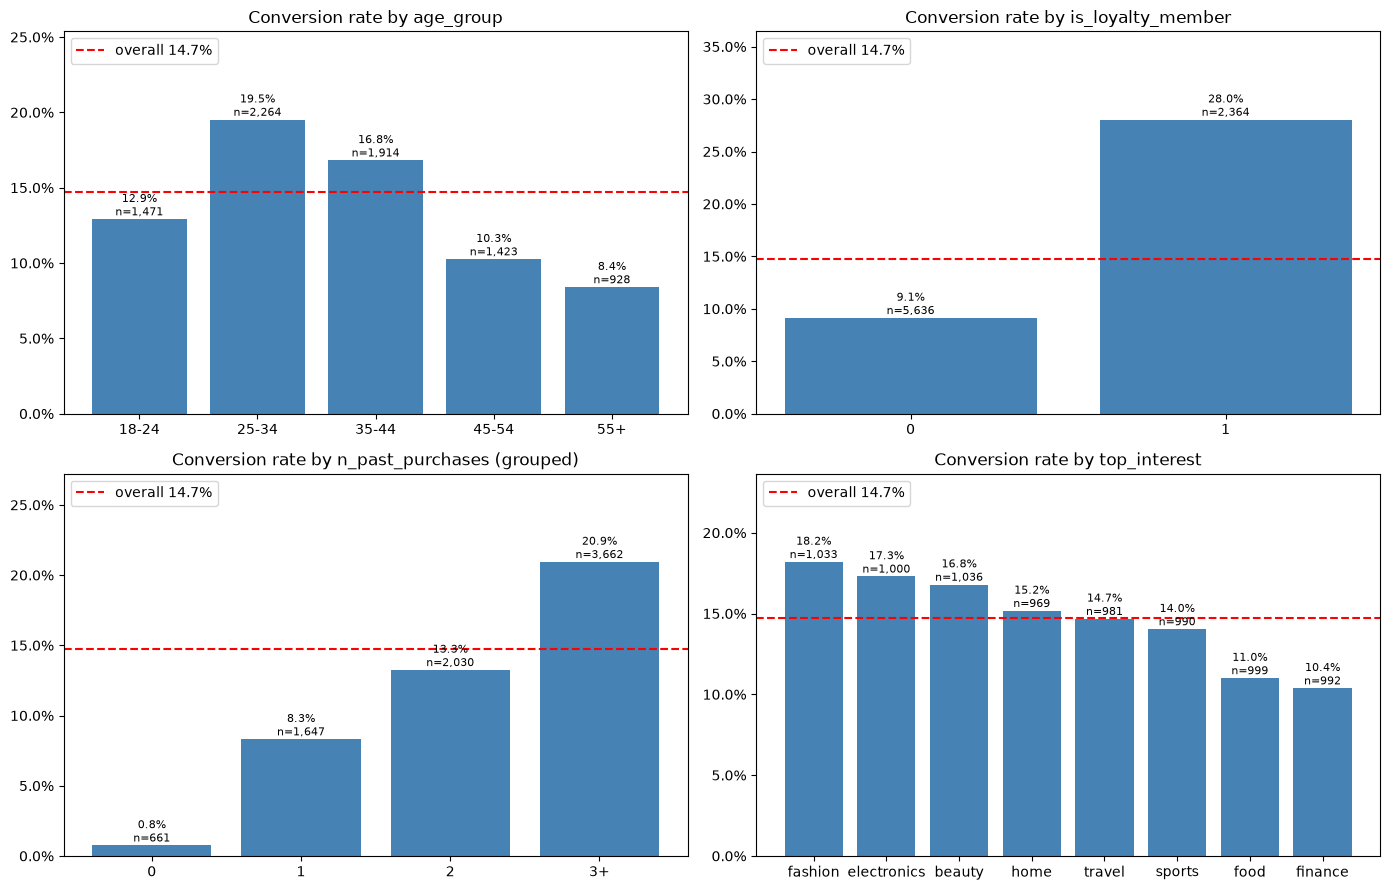

Conversion rate by loyalty x past purchases:


n_past_purchases (grouped),0,1,2,3+
is_loyalty_member,,,,
0,0.002,0.039,0.078,0.137
1,0.018,0.192,0.261,0.387


By n_past_purchases: {0: 0.008, 1: 0.083, 2: 0.133, 3: 0.185, 4: 0.194, 5: 0.258, 6: 0.295, 7: 0.266, 8: 0.483, 9: 0.429, 10: 0.0, 11: 0.0}
Converters with 0 past purchases: 5


In [4]:
# *(3 marks)* Plot conversion rate by:
overall = users['converted'].mean()
past_grp = pd.cut(users['n_past_purchases'], [-1, 0, 1, 2, np.inf], labels=['0', '1', '2', '3+']).rename('n_past_purchases (grouped)')
segments = [users['age_group'], users['is_loyalty_member'], past_grp, users['top_interest']]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, seg in zip(axes.flat, segments):
    rate = users['converted'].groupby(seg, observed=True).agg(['mean', 'size'])
    if seg.name == 'top_interest':
        rate = rate.sort_values('mean', ascending=False)
    ax.bar(rate.index.astype(str), rate['mean'], color='steelblue')
    ax.axhline(overall, color='red', ls='--', label=f'overall {overall:.1%}')
    for i, (m, n) in enumerate(zip(rate['mean'], rate['size'])):
        ax.text(i, m, f'{m:.1%}\nn={n:,}', ha='center', va='bottom', fontsize=8)
    ax.set_ylim(0, rate['mean'].max() * 1.3)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(f'Conversion rate by {seg.name}')
    ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

print('Conversion rate by loyalty x past purchases:')
display(pd.crosstab(users['is_loyalty_member'], past_grp, values=users['converted'], aggfunc='mean').round(3))
print('By n_past_purchases:', users.groupby('n_past_purchases')['converted'].mean().round(3).to_dict())
print('Converters with 0 past purchases:', users.loc[users.n_past_purchases == 0, 'converted'].sum())

**Commentary** - which user characteristics show the strongest relationship with conversion?

The two strongest characteristics are past purchases and loyalty membership. Users who bought nothing in the last 12 months almost never convert (0.8%), while users with 3 or more past purchases convert at 20.9%, and the rate keeps going up for people who bought even more often. Loyalty members convert at 28.0% compared with 9.1% for non-members, about three times higher.

The two effects add up. Loyalty members with 3 or more purchases convert at 38.7%, while non-members with no purchases convert at only 0.2%.

Age has a weaker effect and does not move in one direction. Conversion is highest at 25-34 (19.5%) and 35-44 (16.8%), then falls to 8.4% for 55+. Because it goes up and then down, a single age number (0 to 4) is not enough for a linear model, so in Section 4 I also add one-hot age columns. Interest has a smaller effect, from 18.2% for fashion down to 10.4% for finance.

### 3.3 Ad Engagement Patterns *(4 marks)*

,conversion_rate,users,converters
group,,,
clicked >= 1 ad,0.511,1357,694
"exposed, never clicked",0.075,6224,469
never exposed,0.036,419,15


Conversion rate by number of clicks: {0: 0.073, 1: 0.493, 2: 0.68, 3: 1.0}


,users_exposed,cvr_exposed,users_clicked,cvr_clicked,campaign_name,channel,creative_type,base_cvr,lift_exposed,lift_clicked
campaign_id,,,,,,,,,,
C05,2495,0.176,181,0.597,loyalty_promo,email,newsletter,0.25,1.150,3.889
C02,2500,0.184,174,0.580,summer_sale,search,text_ad,0.20,1.202,3.784
C06,2470,0.178,175,0.566,loyalty_promo,social_media,story_ad,0.11,1.159,3.688
C07,2473,0.174,163,0.546,retargeting,display,dynamic,0.15,1.136,3.559
C04,2547,0.176,199,0.497,new_arrivals,video,pre_roll,0.09,1.147,3.243
C08,2437,0.171,182,0.489,brand_awareness,video,in_stream,0.04,1.113,3.188
C01,2507,0.172,214,0.481,summer_sale,social_media,carousel,0.12,1.123,3.137
C03,2480,0.176,190,0.468,new_arrivals,display,banner,0.05,1.146,3.053


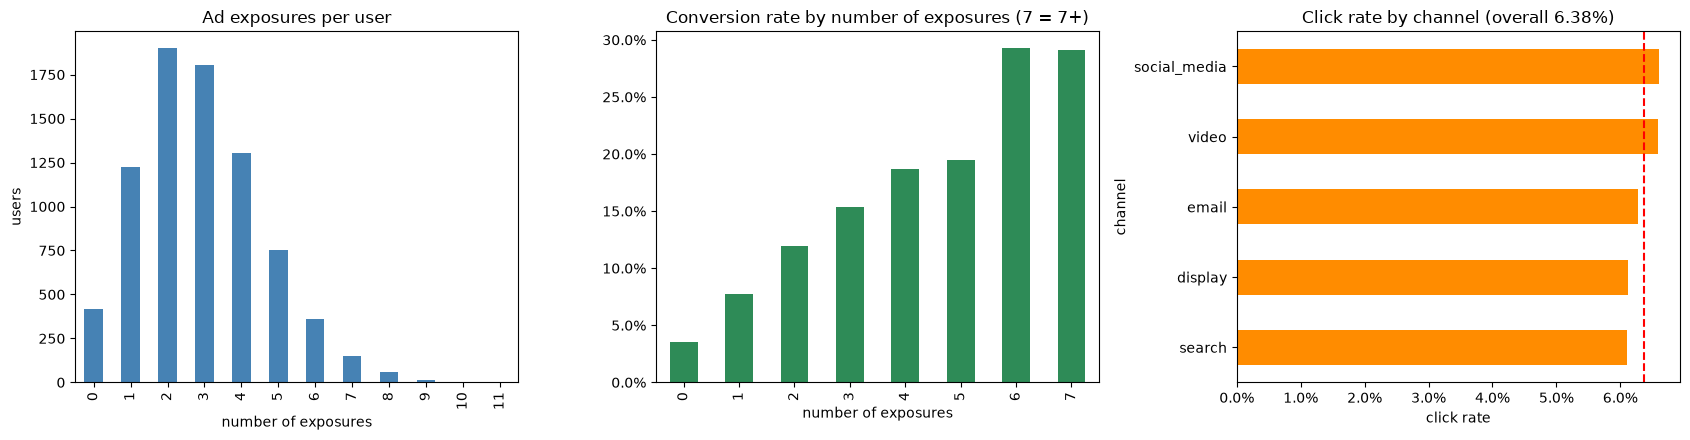

Exposures per user: {'count': 8000.0, 'mean': 2.91, 'std': 1.69, 'min': 0.0, '25%': 2.0, '50%': 3.0, '75%': 4.0, 'max': 11.0}
Click rate by channel: {'search': 0.061, 'display': 0.0612, 'email': 0.0628, 'video': 0.0659, 'social_media': 0.066}
Click rate by ad_position: {1.0: 0.061, 2.0: 0.067, 3.0: 0.068, 4.0: 0.059, 5.0: 0.064}


In [5]:
# *(4 marks)* Explore:
per_user = exposures.groupby('user_id').agg(n_exp=('exposure_id', 'size'), n_clk=('was_clicked', 'sum'))
eng = users[['user_id', 'converted']].merge(per_user, on='user_id', how='left').fillna({'n_exp': 0, 'n_clk': 0})

# (a) clicked >= 1 ad vs not
eng['group'] = np.select([eng.n_exp == 0, eng.n_clk > 0], ['never exposed', 'clicked >= 1 ad'], 'exposed, never clicked')
display(eng.groupby('group')['converted'].agg(conversion_rate='mean', users='size', converters='sum').round(3))
print('Conversion rate by number of clicks:', eng.groupby(eng['n_clk'].astype(int))['converted'].mean().round(3).to_dict())

# (b) conversion rate by campaign: among users who saw it, and among users who clicked it
seen = (exposures.groupby(['user_id', 'campaign_id'])['was_clicked'].max().reset_index()
        .merge(users[['user_id', 'converted']], on='user_id'))
exposed_rate = eng.loc[eng.n_exp > 0, 'converted'].mean()
camp = (seen.groupby('campaign_id').agg(users_exposed=('user_id', 'size'), cvr_exposed=('converted', 'mean'))
        .join(seen[seen.was_clicked == 1].groupby('campaign_id').agg(users_clicked=('user_id', 'size'), cvr_clicked=('converted', 'mean')))
        .join(campaigns.set_index('campaign_id')[['campaign_name', 'channel', 'creative_type', 'base_cvr']]))
camp['lift_exposed'] = camp['cvr_exposed'] / exposed_rate
camp['lift_clicked'] = camp['cvr_clicked'] / exposed_rate
display(camp.sort_values('cvr_clicked', ascending=False).round(3))

# (c) exposures per user and (d) click rate overall / by channel
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
eng['n_exp'].astype(int).value_counts().sort_index().plot.bar(ax=axes[0], color='steelblue')
axes[0].set(title='Ad exposures per user', xlabel='number of exposures', ylabel='users')
eng.groupby(eng['n_exp'].clip(upper=7).astype(int))['converted'].mean().plot.bar(ax=axes[1], color='seagreen')
axes[1].set(title='Conversion rate by number of exposures (7 = 7+)', xlabel='number of exposures')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
ctr = exposures.groupby('channel')['was_clicked'].mean().sort_values()
ctr.plot.barh(ax=axes[2], color='darkorange')
axes[2].axvline(exposures['was_clicked'].mean(), color='red', ls='--')
axes[2].set(title=f"Click rate by channel (overall {exposures['was_clicked'].mean():.2%})", xlabel='click rate')
axes[2].xaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()

print('Exposures per user:', eng['n_exp'].describe().round(2).to_dict())
print('Click rate by channel:', ctr.round(4).to_dict())
print('Click rate by ad_position:', exposures.groupby('ad_position')['was_clicked'].mean().round(3).to_dict())

**Commentary** - which campaign/channel shows the highest conversion lift?

Clicking matters much more than any single campaign. Users who clicked at least one ad converted at 51.1%, users who saw ads without clicking at 7.5%, and users who never saw an ad at 3.6%. Users who saw more ads also converted more, going from 3.6% with no ads to about 29% with six or more.

When I only look at who saw each campaign, the campaigns are very close: between 17.1% and 18.4% of the users who saw each one converted. The highest is C02 (search) at 18.4%. The difference shows up after a click. Users who clicked C05 (email newsletter) converted at 59.7% and users who clicked C02 (search) at 58.0%, which is the highest lift, while clickers of C03 (display banner) converted at 46.8%, the lowest. This agrees with the brief that email and search work better than display. Each campaign only has between 163 and 214 clickers, though, so small differences between campaigns could just be noise.

The click rate itself is about 6% for every channel and every ad position, so the channel seems to affect what happens after the click more than whether people click. I also noticed that `base_cvr` does not match the data. C08 has a base_cvr of 4%, but 17.1% of the users who saw it converted, so I expect `best_campaign_cvr` to be a weak feature.

---
# SECTION 4 - Feature Engineering *(20 marks)*

### 4.1 Aggregate ad exposures per user *(8 marks)*

In [6]:
# *(8 marks)* Create a per-user exposure feature table. Include at least:
SNAPSHOT = exposures['exposure_date'].max()          # "today" for recency = last day in the exposure log
ex = exposures.merge(campaigns[['campaign_id', 'base_cvr']], on='campaign_id', how='left')

exp_feats = ex.groupby('user_id').agg(
    n_exposures=('exposure_id', 'size'),
    n_clicks=('was_clicked', 'sum'),
    n_campaigns_seen=('campaign_id', 'nunique'),
    avg_ad_position=('ad_position', 'mean'),
    last_exposure=('exposure_date', 'max'),
    best_campaign_cvr=('base_cvr', 'max'),
)
exp_feats['click_rate'] = exp_feats['n_clicks'] / exp_feats['n_exposures']
exp_feats['days_since_last_exposure'] = (SNAPSHOT - exp_feats.pop('last_exposure')).dt.days

channel_counts = pd.crosstab(ex['user_id'], ex['channel']).add_prefix('n_')
exp_feats = exp_feats.join(channel_counts)

clicked_campaigns = ex[ex['was_clicked'] == 1].drop_duplicates(['user_id', 'campaign_id'])
exp_feats['total_clicked_cvr'] = clicked_campaigns.groupby('user_id')['base_cvr'].sum()
exp_feats['total_clicked_cvr'] = exp_feats['total_clicked_cvr'].fillna(0)

print('exp_feats shape:', exp_feats.shape)
display(exp_feats.describe().T.round(2))

exp_feats shape: (7581, 13)


,count,mean,std,min,25%,50%,75%,max
n_exposures,7581.0,3.08,1.58,1.00,2.00,3.0,4.00,11.00
n_clicks,7581.0,0.20,0.44,0.00,0.00,0.0,0.00,3.00
n_campaigns_seen,7581.0,2.63,1.21,1.00,2.00,2.0,3.00,8.00
avg_ad_position,7537.0,2.51,0.90,1.00,2.00,2.5,3.00,5.00
best_campaign_cvr,7581.0,0.18,0.06,0.04,0.12,0.2,0.25,0.25
click_rate,7581.0,0.06,0.16,0.00,0.00,0.0,0.00,1.00
days_since_last_exposure,7581.0,13.29,20.32,0.00,0.00,1.0,25.00,112.00
n_display,7581.0,0.76,0.83,0.00,0.00,1.0,1.00,6.00
n_email,7581.0,0.38,0.59,0.00,0.00,0.0,1.00,4.00
n_search,7581.0,0.38,0.60,0.00,0.00,0.0,1.00,3.00


### 4.2 Build master feature table *(8 marks)*

In [7]:
# *(8 marks)* Join exp_feats to users.
master = users.merge(exp_feats, left_on='user_id', right_index=True, how='left')

# Users never served an ad: their counts are genuinely 0
zero_fill = ['n_exposures', 'n_clicks', 'click_rate', 'n_campaigns_seen', 'total_clicked_cvr',
             'best_campaign_cvr'] + list(channel_counts.columns)
master[zero_fill] = master[zero_fill].fillna(0)
master['has_exposure'] = (master['n_exposures'] > 0).astype(int)
# avg_ad_position and days_since_last_exposure mean nothing without an ad, so they stay NaN here.
# SimpleImputer inside each model pipeline fills them (and days_since_last_visit) using the training fold only.

# Encode categoricals
master['age_ord'] = master['age_group'].map({'18-24': 0, '25-34': 1, '35-44': 2, '45-54': 3, '55+': 4})
master['gender_code'] = master['gender'].map({'F': 0, 'M': 1, 'X': 2})
master['device_code'] = master['device_preference'].map({'desktop': 0, 'mobile': 1, 'tablet': 2})
master = master.join(pd.get_dummies(master['top_interest'], prefix='interest', dtype=int))
# Conversion peaks at 25-34 and drops on both sides (3.2), which a single ordinal number
# cannot express in a linear model, so age also gets one-hot columns
master = master.join(pd.get_dummies(master['age_group'], prefix='age', dtype=int))

print('master shape:', master.shape)
print('Columns with nulls:', master.isna().sum()[lambda s: s > 0].to_dict())

master shape: (8000, 39)
Columns with nulls: {'days_since_last_visit': 370, 'avg_ad_position': 463, 'days_since_last_exposure': 419}


***(4 marks)* Feature rationale.**

For each of your three most important features, explain what it measures and why it predicts conversion.
Are there any features that could cause leakage? Explain.

Both models agree on the three most important features.

1. `is_loyalty_member` shows whether the user joined the loyalty programme. Members have already chosen to stay with the brand and they get member offers, so they buy more often: 28.0% of members convert against 9.1% of non-members. When the other features are held the same, the model's odds ratio for membership is about 6.4.
2. `n_past_purchases` counts the purchases in the last 12 months. People who bought before tend to buy again, and each extra purchase multiplies the odds of converting by about 1.55.
3. `n_clicks` counts how many ads the user clicked. A click shows interest in the current offer. Users with one click convert at 49% and users with two clicks at 68%. `click_rate` and `total_clicked_cvr` measure the same behaviour, so I see them as one group.

Some features could cause leakage. `order_value` and `last_campaign_id` only exist for people who bought, so using them would give away the answer, and I left them out. The click and exposure features come from the same period as the target, as explained in 1.3. `n_past_purchases` and `is_loyalty_member` have no date, so if they were recorded after the purchase, the purchase itself would be counted in them. Five users with 0 past purchases still converted, which suggests this is not happening, but I would confirm it with the data team. `days_since_last_exposure` is measured from 1 May 2025, the last day in the log, and in a real system it would have to be calculated from the day we score the users.

---
# SECTION 5 - Training Models *(15 marks)*

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

TARGET  = 'converted'
EXCLUDE = ['user_id','age_group','gender','top_interest','device_preference', TARGET]

feature_cols = [c for c in master.columns if c not in EXCLUDE]
X = master[feature_cols]
y = master[TARGET]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f'Train: {len(X_train):,}  Val: {len(X_val):,}')
print(f'Conversion rate val: {y_val.mean():.2%}')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}

Train: 6,400  Val: 1,600
Conversion rate val: 14.75%


In [9]:
# *(4 marks)* Model 1 - Logistic Regression
from sklearn.linear_model import LogisticRegression

def evaluate(name, model):
    """5-fold CV AUC on train, then fit on the full train split and score train + validation."""
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    model.fit(X_train, y_train)
    results[name] = {
        'cv_auc_mean': cv_auc.mean(),
        'cv_auc_std': cv_auc.std(),
        'train_auc': roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]),
        'val_auc': roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]),
    }
    r = results[name]
    print(f"{name}: CV AUC {r['cv_auc_mean']:.4f} +/- {r['cv_auc_std']:.4f} | train {r['train_auc']:.4f} | val {r['val_auc']:.4f}")
    return model

lr_model = evaluate('Logistic Regression', Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
    ('clf', LogisticRegression(max_iter=2000)),
]))

coefs = pd.Series(lr_model.named_steps['clf'].coef_[0], index=feature_cols).sort_values(key=abs, ascending=False)
print('\nLargest standardised coefficients (log-odds per 1 SD):')
print(coefs.head(10).round(3).to_string())
odds_ratio = pd.Series(np.exp(lr_model.named_steps['clf'].coef_[0] / lr_model.named_steps['scale'].scale_), index=feature_cols)
print('Odds ratio per 1 unit:', odds_ratio[['is_loyalty_member', 'n_past_purchases', 'n_clicks']].round(2).to_dict())
print(f"\nMean predicted probability on val: {lr_model.predict_proba(X_val)[:, 1].mean():.3f} (actual rate {y_val.mean():.3f})")

Logistic Regression: CV AUC 0.8843 +/- 0.0131 | train 0.8898 | val 0.8709

Largest standardised coefficients (log-odds per 1 SD):
is_loyalty_member        0.852
n_clicks                 0.807
n_past_purchases         0.703
age_25-34                0.220
total_clicked_cvr        0.196
interest_finance        -0.180
age_55+                 -0.177
days_since_last_visit   -0.169
avg_ad_position         -0.152
interest_electronics     0.142
Odds ratio per 1 unit: {'is_loyalty_member': 6.45, 'n_past_purchases': 1.55, 'n_clicks': 6.67}

Mean predicted probability on val: 0.151 (actual rate 0.147)


***(3 marks)* Model 1 commentary.**

I put the logistic regression in a pipeline with three steps: fill missing values with the median, scale the features with `StandardScaler`, then fit the model. Scaling matters because logistic regression's regularisation treats all coefficients the same way, so features with large numbers would be treated differently from small ones. It also makes the coefficients comparable with each other. Because everything is inside the pipeline, each CV fold fills and scales its data using only its own training part, so no information leaks from the validation fold.

The results are CV AUC 0.884, validation AUC 0.871 and train AUC 0.890. The gap between train and validation is only 0.019, so the model is not overfitting, and all the scores are above the 0.83 level the brief calls strong.

The largest positive coefficients are loyalty membership, clicks and past purchases. Age 25-34 has a positive effect and 55+ a negative one, which matches the EDA. I also checked the predicted probabilities: on the validation set they average 0.151, very close to the real conversion rate of 0.147. I did not use `class_weight='balanced'`, because it would not improve the ranking and it would make all the probabilities too high.

In [10]:
# *(4 marks)* Model 2 - Random Forest or LightGBM
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

def rf_pipeline(**params):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('clf', RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **params)),
    ])

# Default forest first, to see how far fully grown trees overfit
evaluate('Random Forest (default)', rf_pipeline())

search = RandomizedSearchCV(
    rf_pipeline(),
    {'clf__max_depth': [4, 6, 8, 10, None],
     'clf__min_samples_leaf': [5, 10, 20, 40, 80],
     'clf__max_features': ['sqrt', 0.3, 0.5],
     'clf__class_weight': [None, 'balanced']},
    n_iter=20, cv=cv, scoring='roc_auc', random_state=RANDOM_STATE,
)
search.fit(X_train, y_train)
print('Best params:', search.best_params_)
rf_model = evaluate('Random Forest (tuned)', search.best_estimator_)

Random Forest (default): CV AUC 0.8715 +/- 0.0149 | train 1.0000 | val 0.8506
Best params: {'clf__min_samples_leaf': 20, 'clf__max_features': 0.5, 'clf__max_depth': 10, 'clf__class_weight': 'balanced'}
Random Forest (tuned): CV AUC 0.8836 +/- 0.0152 | train 0.9271 | val 0.8675


***(4 marks)* Model 2 commentary.**

I started with a default random forest to see how it behaves. It reached a train AUC of 1.000 but only 0.851 on validation, so the trees were memorising the training data.

To fix this I tuned it with `RandomizedSearchCV`, trying 20 combinations of `max_depth`, `min_samples_leaf`, `max_features` and `class_weight` with 5-fold CV on the training data. The best setting was `max_depth=10`, `min_samples_leaf=20`, `max_features=0.5` and `class_weight='balanced'`. With smaller trees and at least 20 users in each leaf, the CV AUC rose to 0.884 and the validation AUC to 0.868, and the overfitting gap fell from 0.149 to 0.060.

Random forests do not need scaling because they split on thresholds, but I kept the imputer so both models see the same input. The forest's most important features are loyalty, past purchases and the click features, the same as the logistic regression. It did not beat the logistic regression, probably because the main effects in this data are simple, like "more past purchases means more likely to buy", and a linear model already captures that well.

In [11]:
comparison = pd.DataFrame(results).T
comparison['overfit_gap'] = comparison['train_auc'] - comparison['val_auc']
display(comparison.round(4))

# The two best CV AUCs differ by far less than one CV standard deviation, so I take the simpler model
best_name  = 'Logistic Regression'
best_model = lr_model
best_prob  = best_model.predict_proba(X_val)[:, 1]
print(f'Chosen model: {best_name} (val AUC {roc_auc_score(y_val, best_prob):.4f})')

# Sensitivity: how much of the signal comes from click behaviour?
from sklearn.base import clone
click_cols = ['n_clicks', 'click_rate', 'total_clicked_cvr']
no_click = cross_val_score(clone(lr_model), X_train.drop(columns=click_cols), y_train, cv=cv, scoring='roc_auc')
print(f'Logistic Regression without the 3 click features: CV AUC {no_click.mean():.4f}')

,cv_auc_mean,cv_auc_std,train_auc,val_auc,overfit_gap
Logistic Regression,0.8843,0.0131,0.8898,0.8709,0.0189
Random Forest (default),0.8715,0.0149,1.0000,0.8506,0.1494
Random Forest (tuned),0.8836,0.0152,0.9271,0.8675,0.0596


Chosen model: Logistic Regression (val AUC 0.8709)
Logistic Regression without the 3 click features: CV AUC 0.7898


**Which model did you choose and why?**

I chose the logistic regression. The two models have almost the same CV AUC (0.8843 and 0.8836), and the difference is much smaller than how much the score changes between folds (about 0.013). The validation AUCs are also close (0.871 and 0.868).

Since they perform the same, I prefer the simpler model. The logistic regression overfits less (gap 0.019 against 0.060), its probabilities match the real conversion rate, and its coefficients are easy to explain to a campaign manager.

---
# SECTION 6 - Evaluating Your Model *(8 marks)*

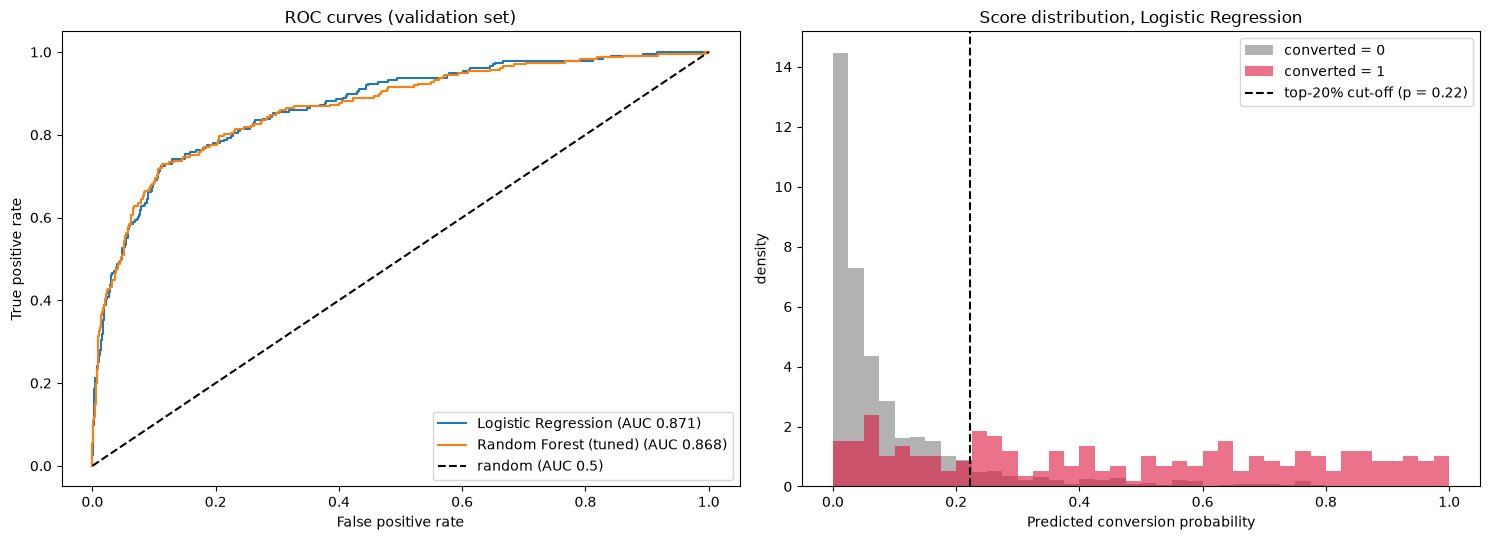

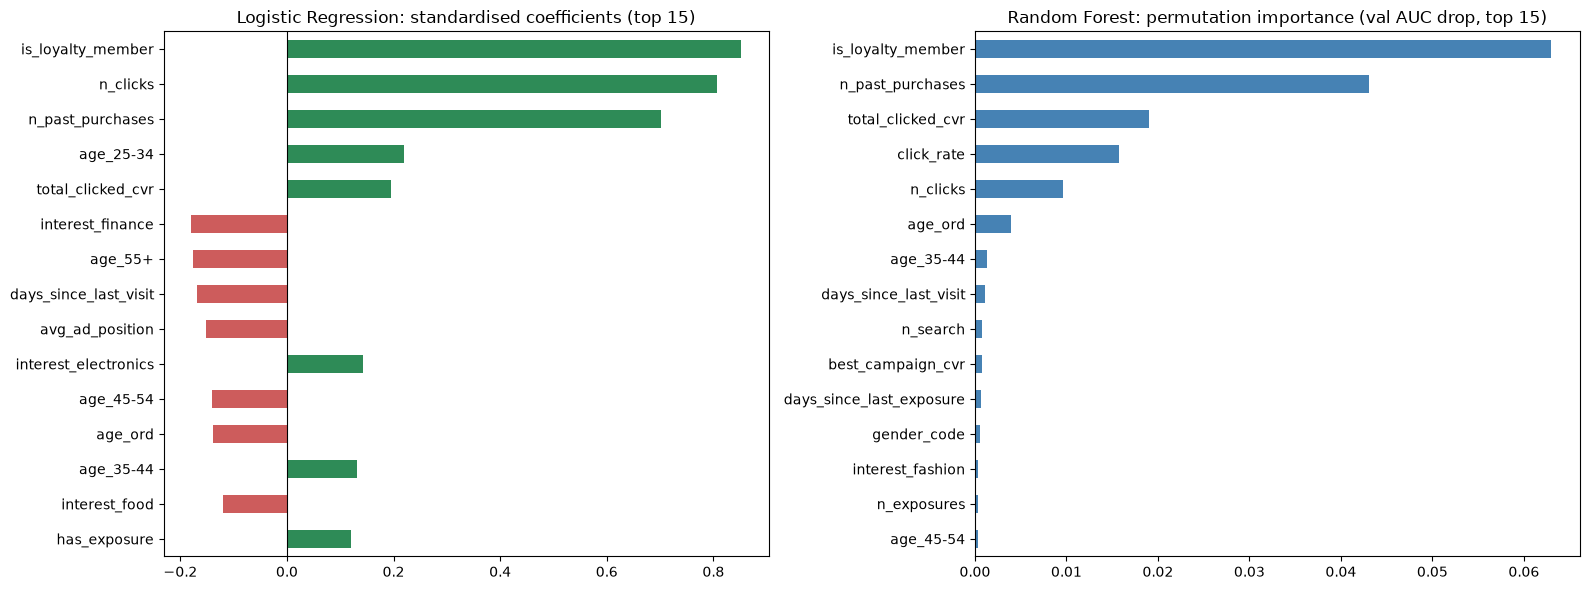

RF permutation importance: {'is_loyalty_member': 0.063, 'n_past_purchases': 0.0431, 'total_clicked_cvr': 0.019, 'click_rate': 0.0157, 'n_clicks': 0.0096, 'age_ord': 0.0039}


In [12]:
# *(8 marks)* Produce:
from sklearn.metrics import roc_curve
from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for name, model in {'Logistic Regression': lr_model, 'Random Forest (tuned)': rf_model}.items():
    p = model.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y_val, p):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', label='random (AUC 0.5)')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves (validation set)')
axes[0].legend(loc='lower right')

top_cut = np.quantile(best_prob, 0.80)
bins = np.linspace(0, 1, 41)
for label, colour in [(0, 'grey'), (1, 'crimson')]:
    axes[1].hist(best_prob[y_val.values == label], bins=bins, alpha=0.6, density=True, color=colour,
                 label=f'converted = {label}')
axes[1].axvline(top_cut, color='black', ls='--', label=f'top-20% cut-off (p = {top_cut:.2f})')
axes[1].set(xlabel='Predicted conversion probability', ylabel='density', title=f'Score distribution, {best_name}')
axes[1].legend()
plt.tight_layout(); plt.show()

perm = permutation_importance(rf_model, X_val, y_val, scoring='roc_auc', n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_top = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False).head(15)
coef_top = coefs.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
coef_top[::-1].plot.barh(ax=axes[0], color=np.where(coef_top[::-1] > 0, 'seagreen', 'indianred'))
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set_title('Logistic Regression: standardised coefficients (top 15)')
perm_top[::-1].plot.barh(ax=axes[1], color='steelblue')
axes[1].set_title('Random Forest: permutation importance (val AUC drop, top 15)')
plt.tight_layout(); plt.show()
print('RF permutation importance:', perm_top.head(6).round(4).to_dict())

**Interpret your diagnostics.**

The ROC curves of the two models are almost on top of each other and both are far above the random line. They rise very steeply at the start: at a 10% false positive rate the model already finds about 70% of the buyers, and that is why targeting the top 20% works so well.

The score distribution shows that most non-buyers get a probability below 0.1. Most buyers get higher scores, between 0.2 and 1.0, and these are mainly users who clicked an ad. There is also a group of buyers with low scores that look like non-buyers. They are the people who bought without clicking any ad, about 41% of all buyers in the data. The model can only find them through loyalty and past purchases, which explains why the top 20% catches 72% of the buyers and not more. The cut-off for the top 20% is a probability of about 0.22, and about half of the users above it really convert.

For feature importance, both models put loyalty, past purchases and clicks at the top. The signs of the coefficients match what I saw in the EDA, for example age 25-34 is positive while 55+ and finance interest are negative. The channel counts and `best_campaign_cvr` hardly matter, which fits Section 3.3, where the campaigns were very similar.

---
# SECTION 7 - Business Impact *(19 marks)*

,capture_rate,users_targeted,conversions_reached,wasted_targets,net_revenue_val_GBP,net_revenue_8000_users_GBP
(a) random 20%,0.20,320,47.2,272.8,4846.0,24228.0
(b) model top 20%,0.72,320,170.0,150.0,19950.0,99750.0


Validation set: 1,600 users, 236 converters, 320 targeted
Random targeting, 1,000 simulations: mean capture 0.199, 90% range 0.157-0.237
Lift at 20%: 3.60x random; extra net revenue on val: GBP 15,104


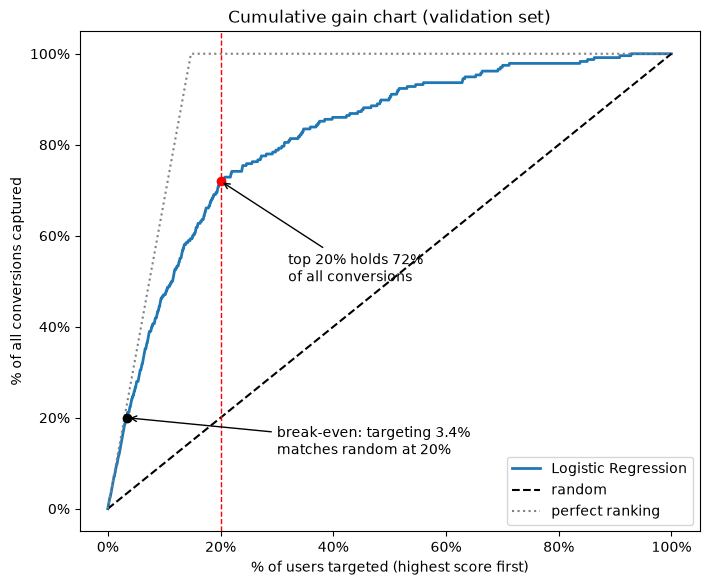

Break-even targeting rate: 3.4% of users
Capture at other budgets: {'5%': 0.271, '10%': 0.47, '20%': 0.72, '30%': 0.788, '50%': 0.903}


,users,conversion_rate,loyalty_member,avg_past_purchases,clicked_any_ad,age_25_44,never_exposed
segment,,,,,,,
other 80%,1280,0.052,0.215,2.341,0.049,0.492,0.072
top 20%,320,0.531,0.569,3.431,0.688,0.684,0.003


Targeting one user pays off on paper when p > 0.024; share of val users above that: 69.2%


In [13]:
# *(10 marks)* Compute conversion capture rate at 20% targeting budget.
REV_PER_CONV, COST_PER_MISS, BUDGET = 120, 3, 0.20

def capture_rate(y_true, scores, frac):
    """Share of all converters that fall inside the top `frac` of users ranked by score."""
    k = int(round(frac * len(scores)))
    top = np.argsort(-scores)[:k]
    return np.asarray(y_true)[top].sum() / np.sum(y_true)

def net_revenue(conversions_reached, n_targeted):
    return REV_PER_CONV * conversions_reached - COST_PER_MISS * (n_targeted - conversions_reached)

y_true = y_val.values
n, n_conv = len(y_true), int(y_true.sum())
k = int(round(BUDGET * n))

model_capture = capture_rate(y_true, best_prob, BUDGET)
rng = np.random.default_rng(RANDOM_STATE)
random_runs = np.array([capture_rate(y_true, rng.random(n), BUDGET) for _ in range(1000)])

impact = pd.DataFrame({'capture_rate': [BUDGET, model_capture]}, index=['(a) random 20%', '(b) model top 20%'])
impact['users_targeted'] = k
impact['conversions_reached'] = impact['capture_rate'] * n_conv
impact['wasted_targets'] = k - impact['conversions_reached']
impact['net_revenue_val_GBP'] = net_revenue(impact['conversions_reached'], k)
impact['net_revenue_8000_users_GBP'] = impact['net_revenue_val_GBP'] * len(master) / n
display(impact.round({'capture_rate': 3, 'conversions_reached': 1, 'wasted_targets': 1,
                      'net_revenue_val_GBP': 0, 'net_revenue_8000_users_GBP': 0}))
print(f'Validation set: {n:,} users, {n_conv} converters, {k} targeted')
print(f'Random targeting, 1,000 simulations: mean capture {random_runs.mean():.3f}, '
      f'90% range {np.percentile(random_runs, 5):.3f}-{np.percentile(random_runs, 95):.3f}')
print(f'Lift at 20%: {model_capture / BUDGET:.2f}x random; extra net revenue on val: '
      f'GBP {impact.net_revenue_val_GBP.diff().iloc[-1]:,.0f}')

# Cumulative gain chart
order = np.argsort(-best_prob)
gain = np.concatenate([[0], np.cumsum(y_true[order]) / n_conv])
pct = np.arange(n + 1) / n
breakeven = pct[np.argmax(gain >= BUDGET)]

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.plot(pct, gain, lw=2, label=best_name)
ax.plot([0, 1], [0, 1], 'k--', label='random')
ax.plot([0, n_conv / n, 1], [0, 1, 1], ':', color='grey', label='perfect ranking')
ax.axvline(BUDGET, color='red', ls='--', lw=1)
ax.scatter([BUDGET], [model_capture], color='red', zorder=3)
ax.annotate(f'top 20% holds {model_capture:.0%}\nof all conversions', (BUDGET, model_capture),
            xytext=(0.32, 0.5), arrowprops=dict(arrowstyle='->'))
ax.scatter([breakeven], [BUDGET], color='black', zorder=3)
ax.annotate(f'break-even: targeting {breakeven:.1%}\nmatches random at 20%', (breakeven, BUDGET),
            xytext=(0.3, 0.12), arrowprops=dict(arrowstyle='->'))
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel='% of users targeted (highest score first)', ylabel='% of all conversions captured',
       title='Cumulative gain chart (validation set)')
ax.legend(loc='lower right')
plt.show()
print(f'Break-even targeting rate: {breakeven:.1%} of users')
print('Capture at other budgets:', {f'{b:.0%}': round(float(capture_rate(y_true, best_prob, b)), 3) for b in [0.05, 0.10, 0.20, 0.30, 0.50]})

# Who is in the top 20%?
val_df = master.loc[X_val.index].assign(score=best_prob)
val_df['segment'] = np.where(val_df['score'] >= np.quantile(best_prob, 1 - BUDGET), 'top 20%', 'other 80%')
profile = val_df.groupby('segment').agg(
    users=('user_id', 'size'), conversion_rate=('converted', 'mean'),
    loyalty_member=('is_loyalty_member', 'mean'), avg_past_purchases=('n_past_purchases', 'mean'),
    clicked_any_ad=('n_clicks', lambda s: (s > 0).mean()), age_25_44=('age_ord', lambda s: s.isin([1, 2]).mean()),
    never_exposed=('has_exposure', lambda s: (s == 0).mean()))
display(profile.round(3))

p_star = COST_PER_MISS / (REV_PER_CONV + COST_PER_MISS)
print(f'Targeting one user pays off on paper when p > {p_star:.3f}; share of val users above that: {(best_prob > p_star).mean():.1%}')

***(9 marks)* Business Recommendations.**

1. How many times better is model targeting vs random at the 20% budget?
2. At what % targeting rate does the model 'break even' vs random (same conversion capture rate as random at 20%)?
3. Which user segments should AdLift prioritise for high-value ad spend?
4. For users with low predicted conversion probability, what lower-cost touchpoints would you recommend?

These numbers come from the validation set (1,600 users, 236 buyers, 320 users targeted):

| | Random 20% | Model top 20% |
|---|---|---|
| Capture rate | 20% | 72% |
| Buyers reached | 47 | 170 |
| Users targeted who do not buy | 273 | 150 |
| Net revenue | £4,846 | £19,950 |

1. With the same budget, the model reaches 3.6 times more buyers than random targeting (72% compared with 20%). Net revenue is about 4 times higher, an extra £15,104 on these 1,600 users.

2. The break-even point is 3.4%. If AdLift only targets the top 3.4% of users by score, it already reaches 20% of all buyers, which is what random targeting gets with 20% of users. In other words, the model gets the same result with about a sixth of the targeting.

3. The users in the model's top 20% look very different from the rest: 57% are loyalty members (21.5% in the other 80%), 69% clicked at least one ad (4.9%), and 68% are aged 25 to 44 (49%). AdLift should spend the most on users who clicked an ad recently, especially from the email and search campaigns, on loyalty members with 3 or more purchases in the last year (38.7% of them convert), and on users aged 25 to 44.

4. The other 80% of users convert at only 5.2%, so expensive display or video ads are mostly wasted on them. Cheaper options would work better: email newsletters, an invitation to join the loyalty programme (members convert three times as often), or a discount code by email to bring back users who have not bought for a while.

One thing to keep in mind is that the £120 per conversion assumes every buyer in the targeted group bought because of the ad. The top users, such as loyal customers and recent clickers, are also the ones most likely to buy anyway. To check how much the ads really add, AdLift could hold back a small random part of the top 20% for a month, show them no ads, and compare how many of them buy.

In [14]:
import joblib
joblib.dump(best_model, 'model.pkl')
print('Model saved to model.pkl')

Model saved to model.pkl


---
# SECTION 8 - Monitoring in Production *(5 marks)*

**8.1** *(2 marks)* AdLift runs new campaigns every month. When a new campaign is launched, some users will be exposed to it for the first time. How would this affect the feature distributions in your model, and how would you detect it?

A new campaign changes several features at once. Users who see it get more exposures and campaigns seen, and the channel counts change if the campaign uses a different channel. Users who had never seen an ad before now have exposures, so their `has_exposure` and recency features change too. The new campaign also brings a new `base_cvr`, which might be outside the range the model saw in training. The model learned from only 8 campaigns, so these changes can make its scores less reliable.

To detect this, I would compare the feature distributions with the training data every time the model scores users, using PSI for each feature and for the score itself. A PSI below 0.1 means little change, and above 0.25 means a big change that needs a closer look. I would also track the share of impressions coming from each channel and campaign.

---

**8.2** *(3 marks)* The conversion rate can spike or drop dramatically around events like Black Friday, Christmas sales, or product launches. How would you monitor for this, and what would trigger a model retraining?

I would track the weekly conversion rate and compare it with the same weeks of last year, with events like Black Friday and Christmas marked on the calendar so an expected spike does not look like a problem. Because we only know who converted 30 days later, I would also compare each month's predictions with what really happened, using AUC and the capture rate at 20%. PSI on the features gives an earlier warning while we wait for those results.

I would retrain the model if the capture rate or AUC drops for two months in a row (for example a capture rate below 60% or an AUC below 0.80), or if the PSI of the score or an important feature goes above 0.25. I would also retrain every month on a schedule using the last 12 months of data, so the model sees every season.

A spike on Black Friday by itself is not a reason to retrain, because it is expected and it ends after a few weeks. If the model is retrained on that data alone, it would learn holiday behaviour as normal. I would first check whether the model still ranks users well during the event.

---
# EXTENSION *(10 marks)*

Attempt **both** tasks (5 marks each).

**E1** *(5 marks)* **SHAP values**: For the top 50 highest-scoring users, use SHAP to identify what drives their predicted conversion probability. Are they dominated by loyalty membership, click behaviour, or campaign type? Plot a SHAP summary plot.

**E2** *(5 marks)* **Attribution**: A user may be exposed to 5 different campaigns before converting. Which campaign gets credit? Research multi-touch attribution models (last-click, linear, time-decay).

### E1 - SHAP values

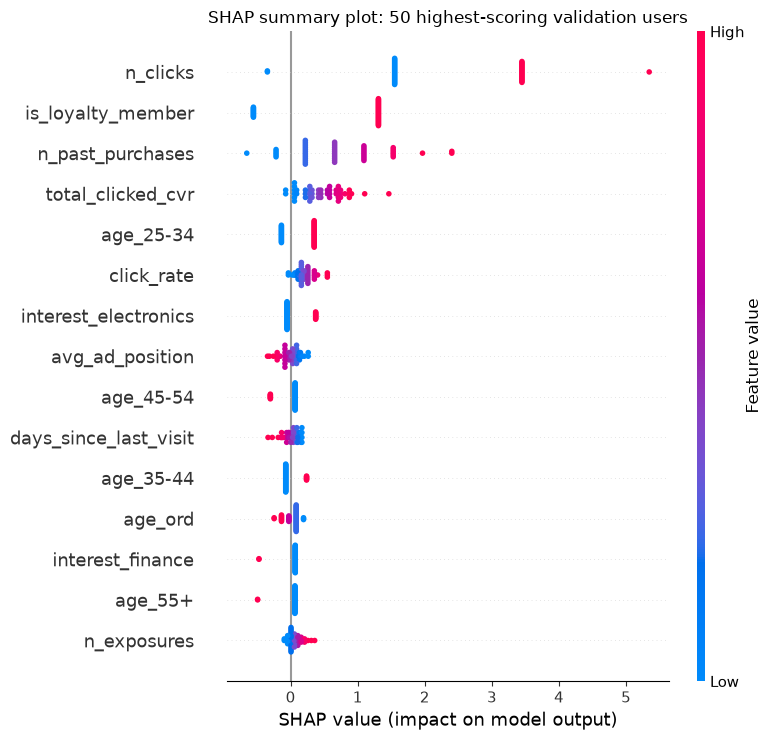

Base value (average log-odds): -2.60 -> p = 0.069
Top 50 users: mean predicted p = 0.898, actual conversion rate = 0.90


,mean,min,max
click behaviour,3.02,-0.46,7.21
loyalty,0.79,-0.56,1.31
past purchases,0.70,-0.65,2.40
demographics & other,0.37,-0.91,1.15
campaign / channel exposure,0.18,-0.58,0.79


Largest positive driver per user: {'click behaviour': 47, 'past purchases': 3}
Loyalty members among top 50: 36 | clicked at least one ad: 48


In [15]:
# E1: SHAP values for the chosen logistic regression
import shap

prep, clf = best_model[:-1], best_model.named_steps['clf']
Z_train = pd.DataFrame(prep.transform(X_train), columns=feature_cols)   # imputed + scaled inputs
Z_val = pd.DataFrame(prep.transform(X_val), columns=feature_cols)

# Background = the whole training set (shap would otherwise sample 100 rows)
explainer = shap.LinearExplainer(clf, shap.maskers.Independent(Z_train, max_samples=len(Z_train)))
sv = explainer(Z_val)
base_value = float(np.ravel(sv.base_values)[0])
# Check: base value + SHAP values = the model's log-odds for every user
assert np.allclose(sv.values.sum(axis=1) + base_value, best_model.decision_function(X_val))

top50 = np.argsort(-best_prob)[:50]
shap.summary_plot(sv.values[top50], Z_val.iloc[top50], max_display=15, show=False)
plt.title('SHAP summary plot: 50 highest-scoring validation users')
plt.tight_layout(); plt.show()

S = pd.DataFrame(sv.values[top50], columns=feature_cols)
groups = {
    'loyalty': ['is_loyalty_member'],
    'past purchases': ['n_past_purchases'],
    'click behaviour': ['n_clicks', 'click_rate', 'total_clicked_cvr'],
    'campaign / channel exposure': ['n_exposures', 'n_campaigns_seen', 'best_campaign_cvr', 'avg_ad_position',
                                    'days_since_last_exposure', 'has_exposure', 'n_display', 'n_email',
                                    'n_search', 'n_social_media', 'n_video'],
}
grouped = set(sum(groups.values(), []))
groups['demographics & other'] = [c for c in feature_cols if c not in grouped]
contrib = pd.DataFrame({g: S[cols].sum(axis=1) for g, cols in groups.items()})
print(f'Base value (average log-odds): {base_value:.2f} -> p = {1 / (1 + np.exp(-base_value)):.3f}')
print(f'Top 50 users: mean predicted p = {best_prob[top50].mean():.3f}, actual conversion rate = {y_val.values[top50].mean():.2f}')
display(contrib.agg(['mean', 'min', 'max']).T.sort_values('mean', ascending=False).round(2))
print('Largest positive driver per user:', contrib.idxmax(axis=1).value_counts().to_dict())
print('Loyalty members among top 50:', int(master.loc[X_val.index[top50], 'is_loyalty_member'].sum()),
      '| clicked at least one ad:', int((master.loc[X_val.index[top50], 'n_clicks'] > 0).sum()))

**E1 result.** I used `shap.LinearExplainer` with the training set as background, which works well for a linear model like logistic regression. The `assert` checks that, for every user, the SHAP values plus the base value add up to the model's output.

The 50 top-scoring users have an average predicted probability of 0.90, and 45 of them really converted. Their scores come mostly from click behaviour. On average, the click features add +3.0 to the log-odds, compared with +0.8 from loyalty, +0.7 from past purchases and only +0.2 from campaign and channel features. Clicks are the biggest driver for 47 of the 50 users, 48 of them clicked at least one ad, and 36 are loyalty members.

So the top users are driven mainly by click behaviour, with loyalty in second place, and the type of campaign they saw matters very little. In the summary plot, `n_clicks` forms separate groups of dots because every extra click adds the same amount in a linear model. Loyalty also has two groups: members get a positive push and the few non-members get a small negative one, and those non-members reach the top 50 thanks to their clicks.

This also means that many of the top users are people who already showed interest, so some of them would probably buy even without more ads.

### E2 - Attribution

1163 converters with an ad path, average path length 3.6 exposures


,last_touch,first_touch,linear,time_decay,last_campaign_id_field,campaign_name,channel,budget_gbp,budget_per_linear_conversion
campaign_id,,,,,,,,,
C01,52.5,167.7,139.1,58.2,139,summer_sale,social_media,25000,179.8
C02,102.5,130.5,157.2,120.9,153,summer_sale,search,40000,254.4
C03,133.0,91.5,141.4,158.3,143,new_arrivals,display,15000,106.1
C04,42.0,211.5,149.3,58.7,144,new_arrivals,video,30000,201.0
C05,17.0,349.2,146.5,20.4,152,loyalty_promo,email,10000,68.3
C06,245.5,80.5,151.6,256.1,148,loyalty_promo,social_media,20000,131.9
C07,234.2,65.3,142.0,254.9,148,retargeting,display,18000,126.8
C08,336.3,66.8,135.9,235.4,136,brand_awareness,video,35000,257.6


last_campaign_id matches one of the user's latest exposures for only 45% of converters


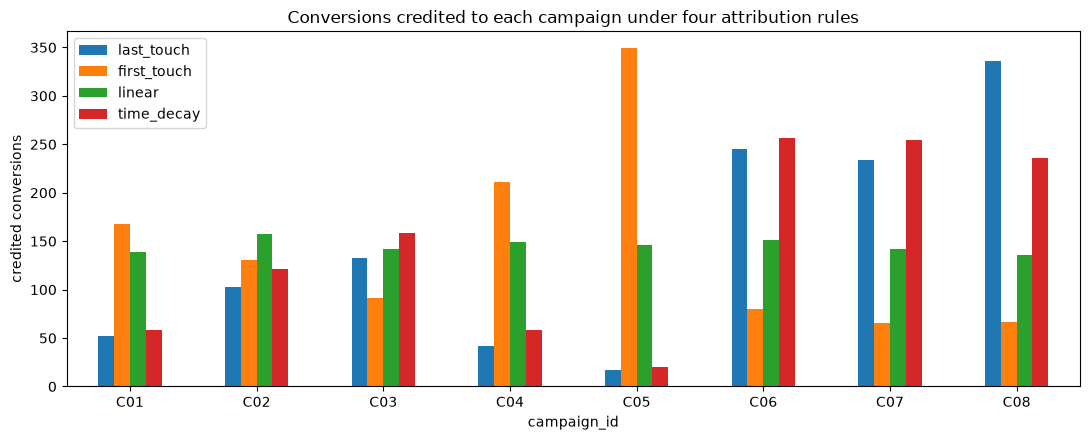

In [16]:
# E2: multi-touch attribution over each converter's exposure path (all exposures happen before conversion)
paths = exposures.merge(conversions[['user_id', 'conversion_date']], on='user_id')
paths = paths[paths['exposure_date'] <= paths['conversion_date']].copy()
paths['days_before'] = (paths['conversion_date'] - paths['exposure_date']).dt.days
by_user = paths.groupby('user_id')

is_last = paths['exposure_date'] == by_user['exposure_date'].transform('max')
is_first = paths['exposure_date'] == by_user['exposure_date'].transform('min')
decay = 0.5 ** (paths['days_before'] / 7)                   # time decay with a 7-day half-life
credit = pd.DataFrame({
    'campaign_id': paths['campaign_id'],
    # exposures on the same last (or first) date split that credit equally: the log has no time of day
    'last_touch': is_last / is_last.groupby(paths['user_id']).transform('sum'),
    'first_touch': is_first / is_first.groupby(paths['user_id']).transform('sum'),
    'linear': 1 / by_user['exposure_id'].transform('size'),
    'time_decay': decay / decay.groupby(paths['user_id']).transform('sum'),
})
attribution = credit.groupby('campaign_id').sum()
attribution['last_campaign_id_field'] = conversions['last_campaign_id'].value_counts()
attribution = attribution.join(campaigns.set_index('campaign_id')[['campaign_name', 'channel', 'budget_gbp']])
attribution['budget_per_linear_conversion'] = attribution['budget_gbp'] / attribution['linear']
print(f'{paths.user_id.nunique()} converters with an ad path, average path length {by_user.size().mean():.1f} exposures')
display(attribution.round(1))

latest = paths[is_last].groupby('user_id')['campaign_id'].apply(set)
check = conversions.set_index('user_id').join(latest.rename('latest')).dropna(subset=['latest'])
share = np.mean([c in s for c, s in zip(check['last_campaign_id'], check['latest'])])
print(f"last_campaign_id matches one of the user's latest exposures for only {share:.0%} of converters")

ax = attribution[['last_touch', 'first_touch', 'linear', 'time_decay']].plot.bar(figsize=(11, 4.5), rot=0)
ax.set(title='Conversions credited to each campaign under four attribution rules', ylabel='credited conversions')
plt.tight_layout(); plt.show()

**E2 result.** When a user sees several campaigns before buying, attribution decides which campaign gets the credit for the sale. The common rules are:

- Last-click gives all the credit to the last campaign the user saw before buying. It is simple, but it ignores the campaigns that first made the user aware of the product.
- First-click gives all the credit to the first campaign, so it ignores everything that happened after.
- Linear splits the credit equally between all the campaigns the user saw.
- Time-decay gives more credit to campaigns closer to the purchase. In my code the weight halves for every 7 days before the purchase.

I applied all four to the 1,163 buyers who saw at least one ad, and the results are very different. Last-click gives C08 (video) 336 conversions and C05 (email) only 17, while first-click gives C05 349. Linear gives every campaign between 136 and 157. The reason is the campaign dates: most ads are recorded on their campaign's last day, so campaigns that ended late, like C08 on 1 May, are almost always "last", and campaigns that ended early, like C05 in February, are almost always "first". In this data, first and last-click mostly reflect when a campaign ran.

I also found that the `last_campaign_id` column matches the user's real last campaign only 45% of the time, so it should not be used for last-click reports until the logging is fixed.

For now I would use linear or time-decay attribution. They are fairer than giving everything to one campaign, but they still only split the credit based on the order of the ads. To know how much each campaign really adds, AdLift should run tests where a random group of users does not see the campaign and compare their purchases with everyone else.